# Building Backtesting Framework and Performance Measurements

The goal of this notebook is to understand how a backtest and PnL curve is generated

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Paths and Global Variables

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
data_path = os.path.join(repo_path, "data")
zone_path = os.path.join(data_path, "ZoneImputedFirstRateData")

In [3]:
day_renamer = {
    "day_after"   : "Day After",
    "day_before"  : "Day Before",
    "post_meeting": "Post Meeting",
    "pre_meeting" : "Pre Meeting"}

zone_renamer = {
    "zone1": "Day Before",
    "zone2": "Before Meeting",
    "zone3": "After Meeting",
    "zone4": "Day After"}

sample_renamer = {
    "lday_vol" : "Prior Day",
    "lzone_vol": "Prior Event"}

vol_renamer = {
    "lday"       : "Prior Day",
    "lzone"      : "Prior Event",
    "combined"   : "Prior Day and Event",
    "raw_rtn"    : "Raw Return",
    "impute_open": "Raw Return"}

param_renamer = {
    "const"    : "Const",
    "lday_vol" : "Prior Day Vol",
    "lzone_vol": "Prio Event Vol"}

tmp_renamer = {
    "name"    : "Trading Zone",
    "vol_type": "Vol Estimator",
    "ticker"  : "Contract"}

replacer = {**day_renamer, **zone_renamer, **sample_renamer, **param_renamer, **vol_renamer, **tmp_renamer}

# Calculating the backtest

One of the problems of generating PnL curves is the following
1. non-continuous times
2. each contract trading at different durations / vols and thus not normalized

In [4]:
path    = os.path.join(data_path, r"ZoneImputedFirstRateData")
df_zone = (pd
    .read_parquet(path = path)
    .loc[lambda x: x.ticker != "ZQ"]
    .set_index("date")
    [["meeting_id", "ticker", "contract", "impute_open", "zone", "name"]])

In [5]:
df_pnl = (df_zone
    .groupby(["meeting_id", "ticker", "contract", "zone", "name"])
    .apply(lambda x: x.sort_index().impute_open.diff())
    .reset_index())

Text(0.5, 1.0, 'Cumulative PnL of Volatility Targeted PnLs Hedged Perfectly and Minutely\nUsing 10d EWMA')

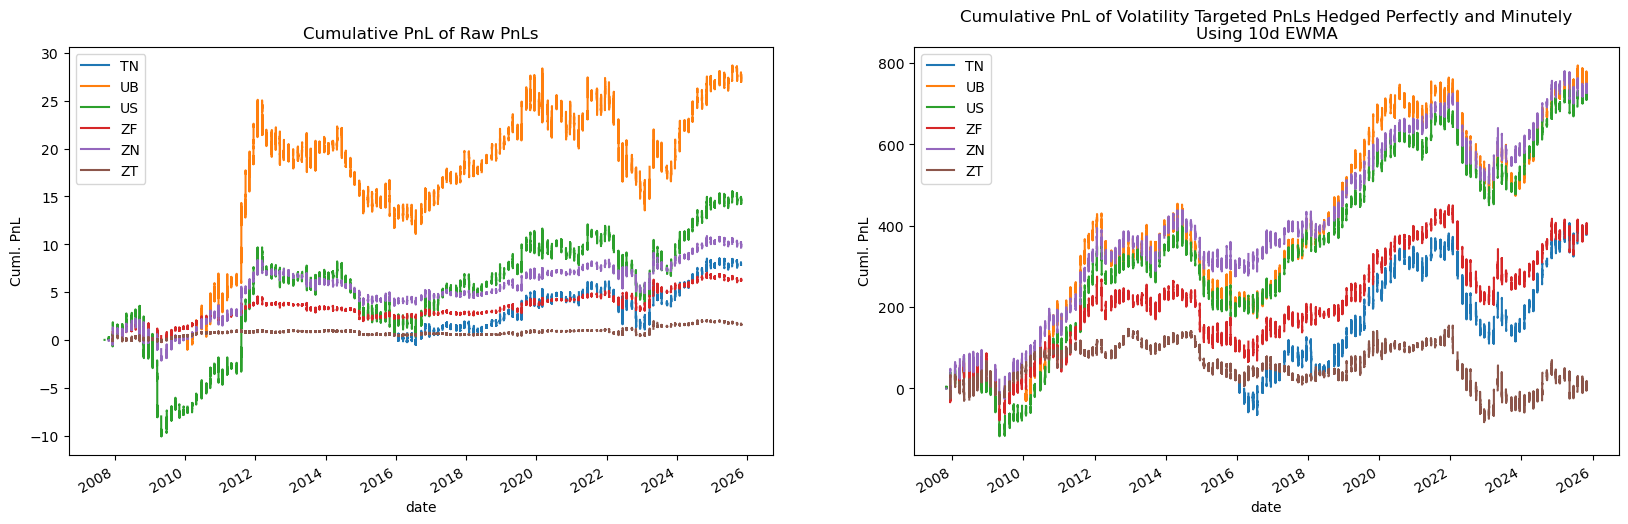

In [6]:
fig, axes = plt.subplots(ncols = 2, figsize = (20,6))

(df_pnl
    .rename(columns = {"ticker": ""})
    .pivot(index = "date", columns = "", values = "impute_open")
    .cumsum()
    .plot(
        ax = axes[0]))

(df_pnl
    .rename(columns = {"ticker": ""})
    .pivot(index = "date", columns = "", values = "impute_open")
    .apply(lambda x: x / x.ewm(span = 10, adjust = False).std())
    .apply(lambda x: np.where(np.abs(x) > 50, np.nan, x))
    .cumsum()
    .plot(
        ax = axes[1]))

for ax in axes.flatten(): 
    ax.set_ylabel("Cuml. PnL")

axes[0].set_title("Cumulative PnL of Raw PnLs")
axes[1].set_title("Cumulative PnL of Volatility Targeted PnLs Hedged Perfectly and Minutely\nUsing 10d EWMA")

The PnLs need some sort of volatility targeting to noramlize the returns when we make the portfolio. On the other hand its not possible to hedge, and perfectly as well, at the minutely level. Therefore we need a volatility targeting tool that does the following
1. Calcluates a hedge value per every trade
2. Keeps the PnL in line with the initial hedge values
3. Also use the prior price action data (which isn't present in the trading zones) data, and thus properly hedge. 

# Finding the optimal volatility calculation

Ideally we want to find a volatility measurement that accurately sets a volatility target. Using the historical data, there are two options 
1. We can use the prior day's volatility calculation which comes from the data
2. We can use the prior event's volatility calculation

At this moment there are arguments for either since the prior day's volatility may capture the macro economic backdrop greater than the prior event, yet the whole point of this repo is to trade a repeatable pattern around FOMC announcements. Therefore we'll test both and see which is better. 

In [7]:
path         = os.path.join(data_path, "Volatilities", "CombinedVolEstimators.parquet")
df_vol_panel = (pd.read_parquet(path = path))

In [8]:
df_day_before = (df_vol_panel
    .loc[lambda x: x.name == "day_before"]
    .assign(
        lzone_vol = lambda x: np.log(x.lzone_vol),
        cur_vol   = lambda x: np.log(x.cur_vol),
        lday_vol  = lambda x: np.log(x.lday_vol)))

C:\Users\Diego\anaconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


When comparing the log volatilities estimators there is a strong linear relationship. Below is a plot showing the relationship between the prior day's volatility (for the corresopnding zone) and the prior event's volatility (prior meeting) volatility. 

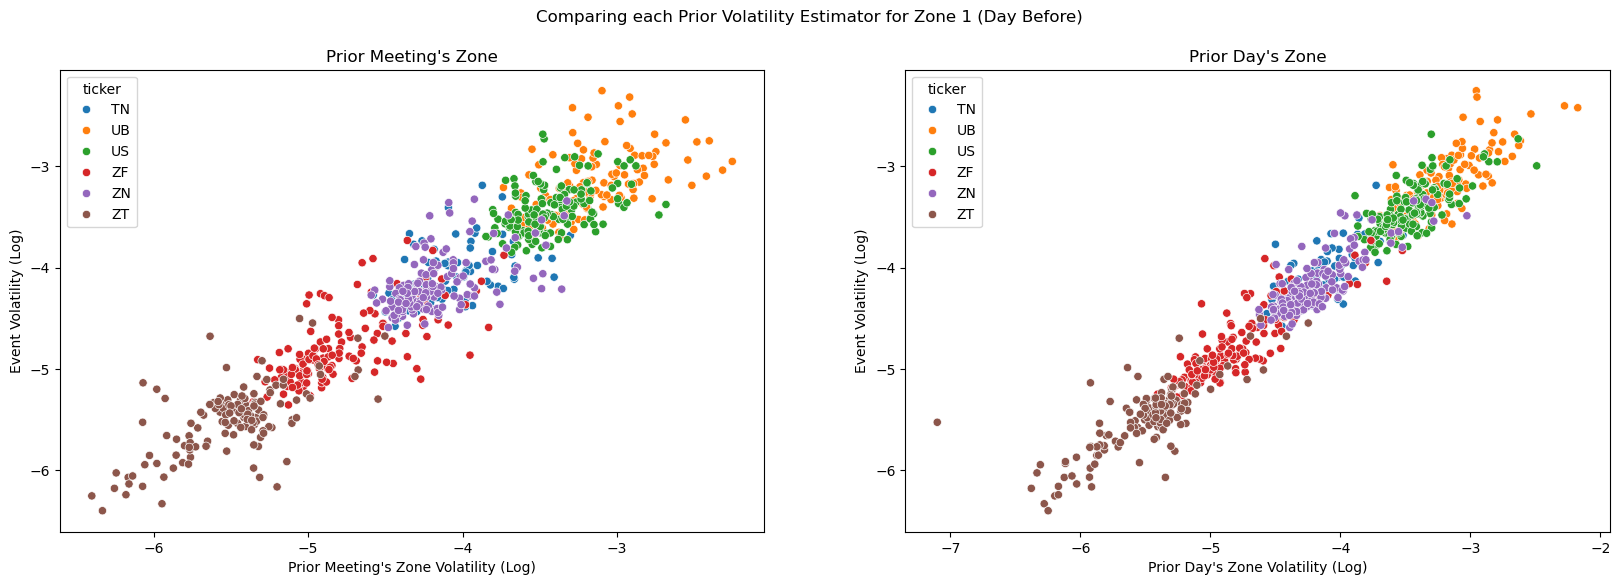

In [9]:
fig, axes   = plt.subplots(ncols = 2, figsize = (20,6))
vol_renamer = {
    "lzone_vol": "Prior Meeting's Zone", 
    "lday_vol" : "Prior Day's Zone"}

for i, vol in enumerate(vol_renamer.keys()):

    sns.scatterplot(
        ax   = axes[i],
        data = df_day_before,
        x    = vol,
        y    = "cur_vol",
        hue  = "ticker")

    axes[i].set_ylabel("Event Volatility (Log)")
    axes[i].set_xlabel(vol_renamer[vol] + " Volatility (Log)")
    axes[i].set_title(vol_renamer[vol])

fig.suptitle("Comparing each Prior Volatility Estimator for Zone 1 (Day Before)")
plt.show()

In [10]:
df_tn_vol = (df_vol_panel
    .loc[lambda x: x.ticker == x.ticker.min()]
    [["name", "lzone_vol", "cur_vol", "lday_vol"]]
    .set_index("name")
    .reset_index()
    .replace(replacer))

It appears that the relationship is not strong when comparing them across different zones. This implies that different periods around FOMC announcements have non uniform volatility structures. Notice on the left hand of the plot the prior meeting times appears to have a more linear relationship than the prior day's. This shows that it was right to be cautious about using the prior day's volatility. 

Text(0.5, 0.98, 'Comparing each Prior Volatility Estimator for TN Futures')

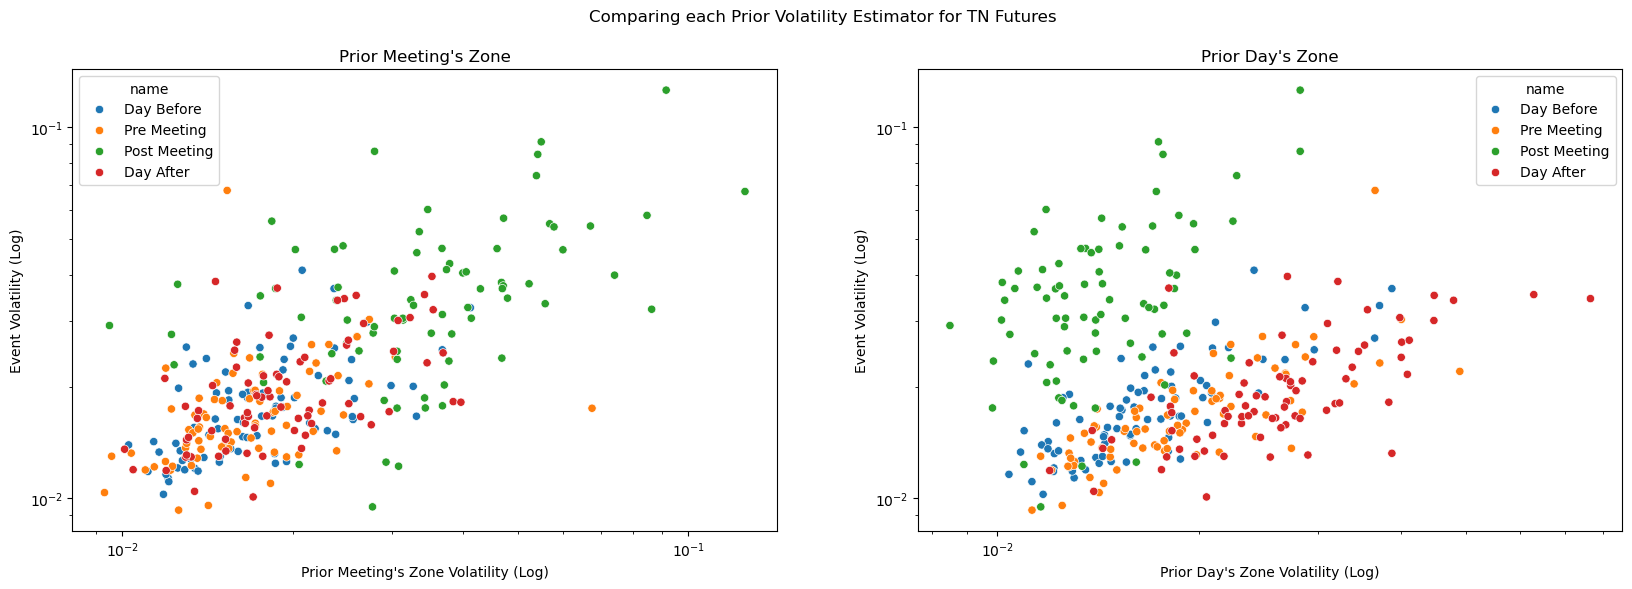

In [11]:
fig, axes   = plt.subplots(ncols = 2, figsize = (20,6))
vol_renamer = {
    "lzone_vol": "Prior Meeting's Zone", 
    "lday_vol" : "Prior Day's Zone"}

for i, vol in enumerate(vol_renamer.keys()):

    sns.scatterplot(
        ax   = axes[i],
        data = df_tn_vol,
        x    = vol,
        y    = "cur_vol",
        hue  = "name")

    axes[i].set_xscale("log")
    axes[i].set_yscale("log")
    
    axes[i].set_ylabel("Event Volatility (Log)")
    axes[i].set_xlabel(vol_renamer[vol] + " Volatility (Log)")
    axes[i].set_title(vol_renamer[vol])

fig.suptitle("Comparing each Prior Volatility Estimator for TN Futures")

Before setting up the first model for testing start by deciding if we have enough data to begin. Below is a table its reasonable but we have to consider that a full out-of-sample model diminishes the data size. 

In [12]:
(df_vol_panel
    [["ticker", "name", "lag_contract"]]
    .groupby(["ticker", "name"])
    .agg("count")
    .reset_index()
    .rename(columns = {"name": ""})
    .pivot(index = "ticker", columns = "", values = "lag_contract")
    .rename(columns = replacer))

,Day After,Day Before,Post Meeting,Pre Meeting
ticker,,,,
TN,77,78,77,78
UB,126,126,126,126
US,145,145,144,144
ZF,142,141,140,142
ZN,143,143,142,142
ZT,143,143,143,142


When comparing raw correlations it appears that the the prior day volatility is a better estimator

In [13]:
df_vol_corr = (df_vol_panel
    [["ticker", "name", "cur_vol", "lzone_vol", "lday_vol"]]
    .melt(id_vars = ["ticker", "name", "cur_vol"])
    .groupby(["ticker", "name", "variable"])
    .agg("corr")
    .reset_index()
    .drop(columns = ["level_3", "cur_vol"])
    .loc[lambda x: x.value != 1])

display(df_vol_corr
    .rename(columns = {"name": ""})
    .replace(replacer)
    .pivot(index = ["ticker", "variable"], columns = "", values = "value"))

Day After  Day Before  Post Meeting  Pre Meeting
ticker variable                                                        
TN     Prio Event Vol   0.502237    0.481407      0.518249     0.212476
       Prior Day Vol    0.633238    0.768213      0.592879     0.643383
UB     Prio Event Vol   0.475043    0.418571      0.407737     0.250602
       Prior Day Vol    0.627908    0.752141      0.511992     0.560531
US     Prio Event Vol   0.331088    0.413897      0.256174     0.198990
       Prior Day Vol    0.377306    0.419062      0.426415     0.522958
ZF     Prio Event Vol   0.386387    0.619376      0.475947     0.304388
       Prior Day Vol    0.463760    0.829419      0.591029     0.684044
ZN     Prio Event Vol   0.366195    0.534727      0.436068     0.298285
       Prior Day Vol    0.378734    0.808704      0.533474     0.626716
ZT     Prio Event Vol   0.588373    0.614421      0.574599     0.396211
       Prior Day Vol    0.670684    0.816100      0.305442     0.748744

The Prior Day volatility estimate adds a reasonable amount of extra correlation for almost all scenarios

In [14]:
(df_vol_corr
    .pivot(index = ["ticker", "name"], columns = "variable", values = "value")
    .assign(extra_corr = lambda x: x.lday_vol - x.lzone_vol)
    .reset_index()
    .rename(columns = {"name": ""})
    .replace(replacer)
    .pivot(index = "ticker", columns = "", values = "extra_corr"))

,Day After,Day Before,Post Meeting,Pre Meeting
ticker,,,,
TN,0.131001,0.286806,0.074630,0.430907
UB,0.152865,0.333570,0.104255,0.309930
US,0.046218,0.005165,0.170241,0.323968
ZF,0.077373,0.210043,0.115082,0.379656
ZN,0.012538,0.273977,0.097406,0.328431
ZT,0.082310,0.201679,-0.269157,0.352533


There is reason to believe that adding the Lagged Perior Volatility since the correlation between the two exoegenous factors is quite low. 

In [15]:
(df_vol_panel
    [["ticker", "name", "lzone_vol", "lday_vol"]]
    .groupby(["ticker", "name"])
    .agg("corr")
    .loc[lambda x: x.lday_vol != 1]
    .reset_index()
    .rename(columns = {"name": ""})
    .replace(replacer)
    .pivot(index = "ticker", columns = "", values = "lday_vol"))

,Day After,Day Before,Post Meeting,Pre Meeting
ticker,,,,
TN,0.429402,0.482172,0.441947,0.311838
UB,0.383314,0.473031,0.335469,0.268674
US,0.220396,0.195895,0.250763,0.250457
ZF,0.390400,0.570838,0.374510,0.380270
ZN,0.367540,0.542325,0.361849,0.362061
ZT,0.464224,0.581968,0.148377,0.517937


Now start by analyzing the full sample OLS parameters. 3 regressions are run per group per ticker
1. Using prior day volatility
2. Using prior event volatility
3. Using Both

In [16]:
path      =  os.path.join(data_path, "Volatilities", "CombinedVolOLSParams.parquet")
df_params = pd.read_parquet(path = path, engine = "pyarrow")

With the OLS parameters we see that the number of statistically significant parameters is quite high. Below is the ratio of parameters with $t$-values higher that |1.5| and $p$-values less than 5%

In [17]:
(df_params
    .assign(stat_sig = lambda x: np.where((np.abs(x.tvalue) > 1.5) & (x.pvalue < 0.05), "good", "bad"))
    [["index", "stat_sig", "tvalue"]]
    .groupby(["index", "stat_sig"])
    .agg("count")
    .reset_index()
    .rename(columns = {
        "index"   : "",
        "stat_sig": "Stat Sig"})
    .pivot(index = "", columns = "Stat Sig", values = "tvalue")
    .fillna(0)
    .assign(
        cuml      = lambda x: x.sum(axis = 1),
        pos_ratio = lambda x: x.good / x.cuml)
    [["pos_ratio"]]
    .rename(columns = {"pos_ratio": "Stat Sig Rate"})
    .T
    .rename(columns = replacer))

,Const,Prior Day Vol,Prio Event Vol
Stat Sig,,,
Stat Sig Rate,0.791667,1.0,0.8125


In [18]:
df_r2 = (df_params
    [["name", "adj_r2", "ticker", "zone", "vol_type"]]
    .drop_duplicates())

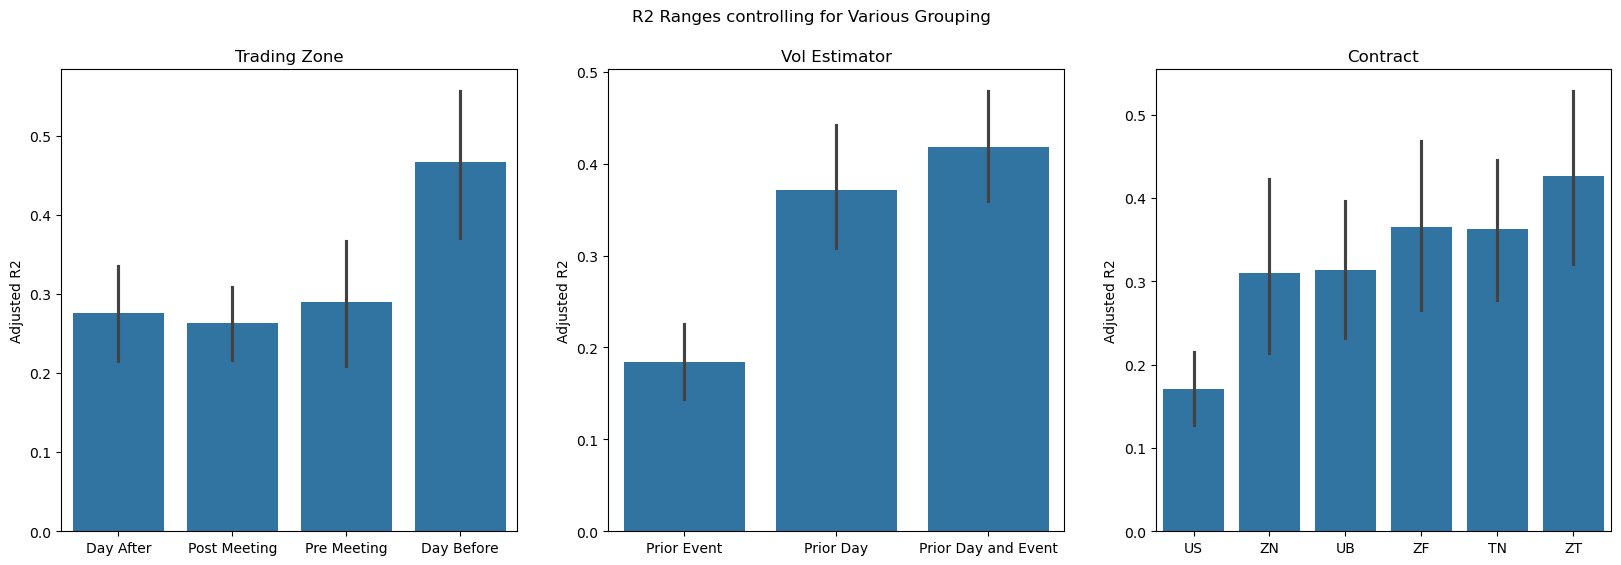

In [19]:
cols      = ["name", "vol_type", "ticker"]
fig, axes = plt.subplots(ncols = len(cols), figsize = (20,6))

for col, ax in zip(cols, axes.flatten()): 

    df_plot = df_r2.replace(replacer)
    
    order = (df_plot
        .groupby(col)["adj_r2"]
        .median()
        .sort_values()
        .index)

    sns.barplot(
        ax    = ax,
        data  = df_plot,
        x     = col,
        y     = "adj_r2",
        order = order)

    ax.set_ylabel("Adjusted R2")
    ax.set_title(replacer[col])
    ax.set_xlabel("")

fig.suptitle("R2 Ranges controlling for Various Grouping")
plt.show()

In [20]:
cols     = ["name", "vol_type", "ticker"]
df_lists = [] 

for col in cols: 

    df_add = (df_params
        [[col, "adj_r2"]]
        .groupby(col)
        .agg("mean")
        .reset_index()
        .rename(columns = {col: "stat"})
        .assign(name = col))
    
    df_lists.append(df_add)

In [21]:
df_avg_r2 = (pd
    .concat(df_lists)
    .replace(replacer)
    .sort_values("adj_r2")
    .rename(columns = {"name": ""}))

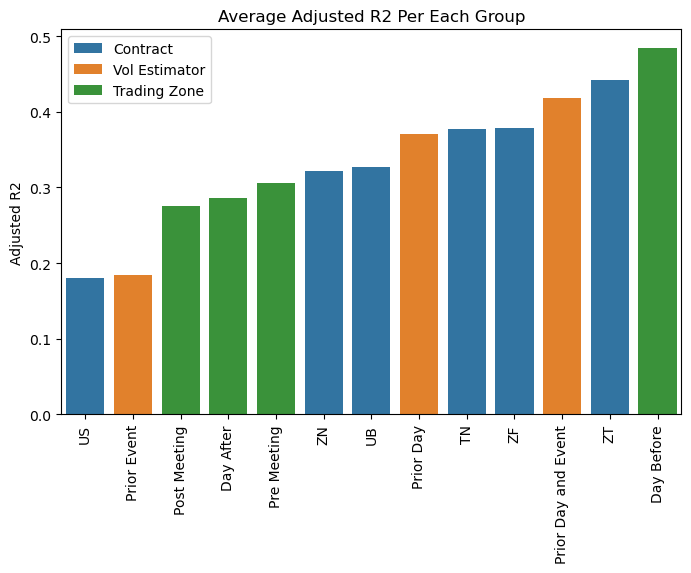

In [22]:
fig, axes = plt.subplots(figsize = (8,5))

sns.barplot(
    data = df_avg_r2,
    x    = "stat",
    y    = "adj_r2",
    hue  = "",
    ax   = axes)

axes.tick_params(axis = "x", rotation = 90)
axes.set_xlabel("")
axes.set_ylabel("Adjusted R2")
axes.set_title("Average Adjusted R2 Per Each Group")
plt.show()

# Building In-Sample Backtest

Now that the volatility estimator is built we can build generic in-sample time series of our events

In [23]:
path        = os.path.join(data_path, "InSampleBacktest", "InSampleBacktest.parquet")
df_backtest = pd.read_parquet(path = path)

In [24]:
df_longer = (df_backtest
    .pivot(index = ["date", "ticker", "impute_open"], columns = "vol_type", values = "vol_rtn")
    .reset_index()
    .melt(id_vars = ["date", "ticker"])
    .dropna())

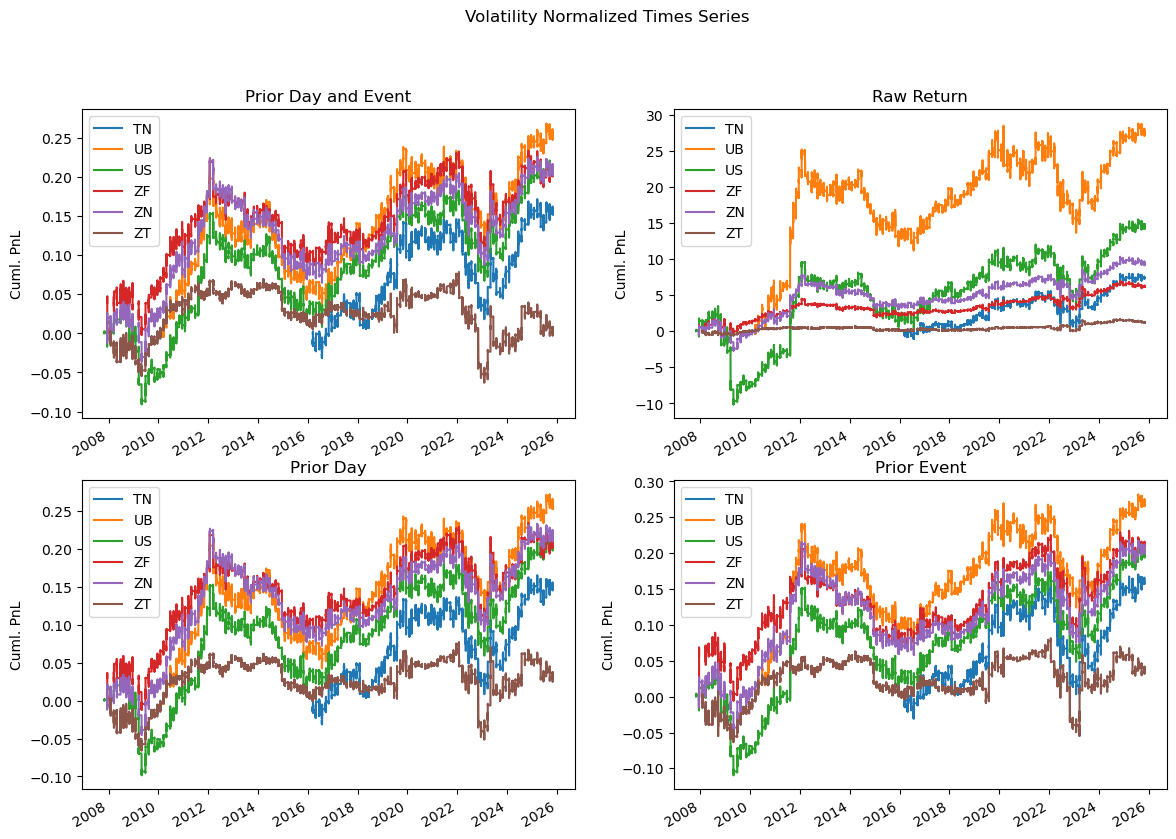

In [25]:
vol_types = df_longer.vol_type.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(vol_types) // 2, nrows = len(vol_types) // 2, figsize = (14, 10))

for vol_type, ax in zip(vol_types, axes.flatten()): 
    
    (df_longer
        .loc[lambda x: x.vol_type == vol_type]
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "value")
        .cumsum()
        .plot(
            ax     = ax,
            title  = replacer[vol_type],
            ylabel = "Cuml. PnL",
            xlabel = ""))

fig.suptitle("Volatility Normalized Times Series")
plt.show()

In [26]:
df_corr = (df_longer
    .pivot(index=["date", "ticker"], columns="vol_type", values="value")
    .groupby("ticker")
    .corr()
    .reset_index()
    .rename(columns={"level_1": "vol_type"})
    .melt(id_vars=["ticker", "vol_type"], var_name="vol_type_2", value_name="corr")
    .loc[lambda x: x.vol_type != x.vol_type_2]
    .groupby("ticker", as_index=False)
    .agg(avg_corr=("corr", "mean"))
    .set_index("ticker")
    .T
    .assign(Avg = lambda x: x.mean(axis = 1)))

In [27]:
display(df_corr)

ticker,TN,UB,US,ZF,ZN,ZT,Avg
avg_corr,0.96512,0.971274,0.984951,0.955437,0.974627,0.957772,0.968197


Now compare how different their sharpes are for each volatility estimation method

In [28]:
(df_longer
    .drop(columns = ["date"])
    .groupby(["ticker", "vol_type"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(390 * 8))
    .reset_index()
    .rename(columns = {"vol_type": ""})
    .pivot(index = "ticker", columns = "", values = "value")
    .rename(columns = replacer))

,Prior Day and Event,Raw Return,Prior Day,Prior Event
ticker,,,,
TN,0.208322,0.237170,0.199299,0.210596
UB,0.208640,0.219495,0.211750,0.217099
US,0.152513,0.139651,0.146519,0.142036
ZF,0.152071,0.206219,0.151614,0.149302
ZN,0.151870,0.180795,0.157068,0.147321
ZT,0.001579,0.088533,0.022165,0.027576


# Generic Backtest

Now we'll create a generic backtest by taking the average return during each period (full sample), and then trading that signal

In [38]:
df_signal = (df_backtest
    [["ticker", "zone", "name", "vol_type", "vol_rtn"]]
    .dropna()
    .groupby(["ticker", "zone", "name", "vol_type"])
    .agg("mean")
    .reset_index()
    .rename(columns = {"vol_rtn": "signal"}))

In [45]:
df_signal_rtn = (df_backtest
    [["date", "ticker", "vol_type", "vol_rtn", "zone", "name"]]
    .merge(right = df_signal, how = "inner", on = ["ticker", "vol_type", "zone", "name"])
    .assign(signal_rtn = lambda x: np.sign(x.signal) * x.vol_rtn))

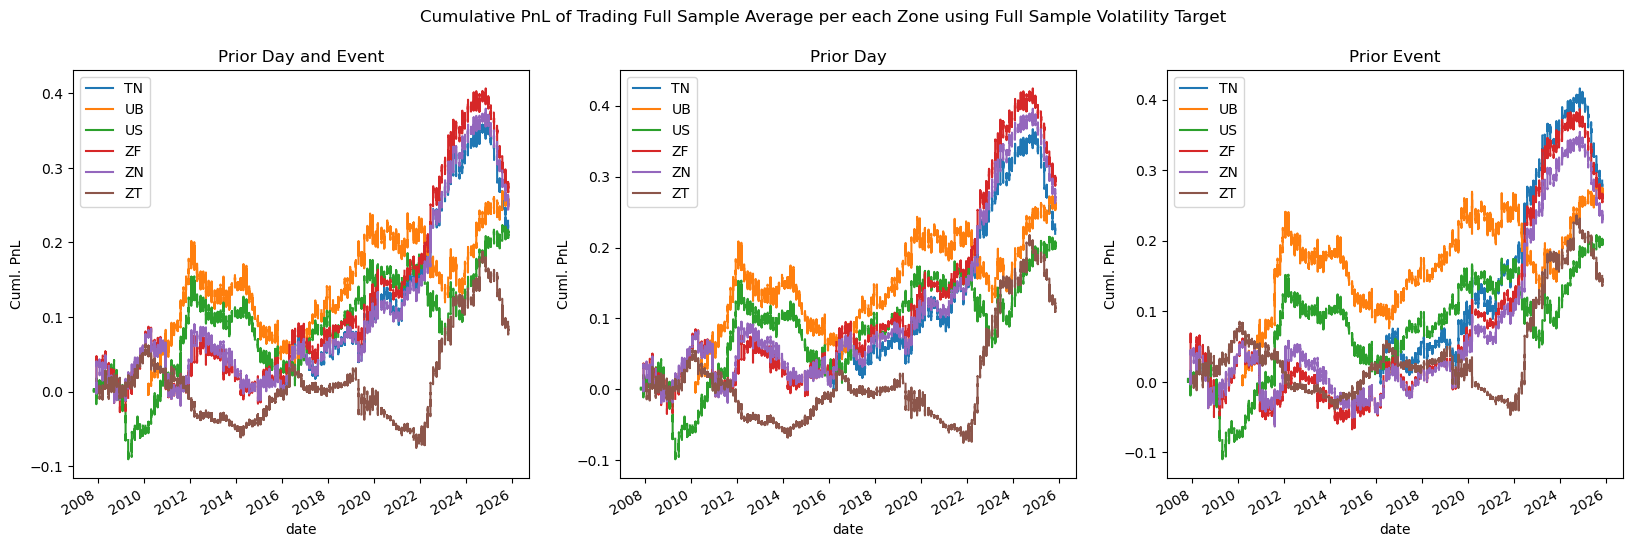

In [58]:
vol_types = df_signal_rtn.vol_type.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(vol_types), figsize = (20,6))

for vol_type, ax in zip(vol_types, axes.flatten()):

    (df_signal_rtn
        .loc[lambda x: x.vol_type == vol_type]
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "signal_rtn")
        .cumsum()
        .plot(
            ax     = ax,
            ylabel = "Cuml. PnL",
            title  = replacer[vol_type]))

fig.suptitle("Cumulative PnL of Trading Full Sample Average per each Zone using Full Sample Volatility Target")
plt.show()

In [77]:
df_zone_vol = (df_signal_rtn
    [["ticker", "vol_type", "name", "signal_rtn"]]
    .dropna()
    .groupby(["ticker", "vol_type", "name"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(390 * 8))
    .reset_index())

In [78]:
df_all_sharpe = (df_signal_rtn
    [["ticker", "vol_type", "signal_rtn"]]
    .dropna()
    .groupby(["ticker", "vol_type"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(390 * 8))
    .assign(name = "All")
    .reset_index())

In [88]:
(pd
    .concat([df_zone_vol, df_all_sharpe])
    .rename(columns = {
        "ticker"  : "Ticker",
        "vol_type": "Vol. Target",
        "name"    : ""})
    .replace(replacer)
    .pivot(index = ["Ticker", "Vol. Target"], columns = "", values = "signal_rtn")
    .apply(lambda x: np.round(x,3)))

All  Day After  Day Before  Post Meeting  \
Ticker Vol. Target                                                       
TN     Prior Day            0.300      0.022       0.144         1.314   
       Prior Day and Event  0.296      0.030       0.124         1.295   
       Prior Event          0.367      0.100       0.224         1.179   
UB     Prior Day            0.212      0.073       0.172         0.784   
       Prior Day and Event  0.209      0.059       0.183         0.734   
       Prior Event          0.217      0.036       0.170         0.808   
US     Prior Day            0.147      0.152       0.074         0.467   
       Prior Day and Event  0.153      0.138       0.108         0.465   
       Prior Event          0.142      0.126       0.108         0.438   
ZF     Prior Day            0.214      0.244       0.092         1.130   
       Prior Day and Event  0.200      0.249       0.071         1.036   
       Prior Event          0.185      0.281       0.053         1.056   
ZN     Prior Day            0.196      0.214       0.056         1.068   
       Prior Day and Event  0.183      0.213       0.045         0.964   
       Prior Event          0.167      0.215       0.028         0.968   
ZT     Prior Day            0.086      0.015       0.057         0.682   
       Prior Day and Event  0.063      0.034       0.053         0.311   
       Prior Event          0.106      0.107       0.060         0.453   

                            Pre Meeting  
Ticker Vol. Target                       
TN     Prior Day                  0.682  
       Prior Day and Event        0.683  
       Prior Event                0.751  
UB     Prior Day                  0.328  
       Prior Day and Event        0.332  
       Prior Event                0.393  
US     Prior Day                  0.162  
       Prior Day and Event        0.160  
       Prior Event                0.137  
ZF     Prior Day                  0.102  
       Prior Day and Event        0.097  
       Prior Event                0.004  
ZN     Prior Day                  0.146  
       Prior Day and Event        0.138  
       Prior Event                0.089  
ZT     Prior Day                  0.053  
       Prior Day and Event        0.052  
       Prior Event                0.077

In [99]:
(pd
    .concat([df_zone_vol, df_all_sharpe])
    .drop(columns = ["name"])
    .groupby(["ticker", "vol_type"])
    .agg("mean")
    .reset_index()
    .pivot(index = "ticker", columns = "vol_type", values = "signal_rtn")
    .sort_values(["combined", "lday", "lzone"]))

vol_type,combined,lday,lzone
ticker,,,
ZT,0.102447,0.178552,0.160979
US,0.204512,0.200380,0.190396
UB,0.303390,0.313553,0.324709
ZN,0.308652,0.335854,0.293090
ZF,0.330410,0.356474,0.315685
TN,0.485584,0.492536,0.524162


In [102]:
(pd
    .concat([df_zone_vol, df_all_sharpe])
    .drop(columns = ["ticker"])
    .groupby(["vol_type", ""]))

,vol_type,name,signal_rtn
0,combined,day_after,0.029807
1,combined,day_before,0.124377
2,combined,post_meeting,1.294590
3,combined,pre_meeting,0.683462
4,lday,day_after,0.022264
...,...,...,...
13,lday,All,0.195913
14,lzone,All,0.166657
15,combined,All,0.062564
16,lday,All,0.086031
